# **Otimização de Algoritmos de Recomendação via Dinâmica de Sistemas de EDOs**

**Disciplina:** Métodos Numéricos Computacionais — Centro de Informática (CIn / UFPE)  
**Grupo 05:**  
- Andreywid Yago Lima de Souza (`ayls@cin.ufpe.br`)  
- Artur Vinicius Pereira Fernandes (`avpf@cin.ufpe.br` / `arturvpf3@gmail.com`)  
- Breno Ramos de Souza Gomes (`brsg@cin.ufpe.br`)  
- Valter Sanches Martins Neto (`vsmn@cin.ufpe.br`)  
- Manoel Lira de Carvalho (`mlc6@cin.ufpe.br`)

## 1. Introdução

A era digital transformou radicalmente a maneira como interagimos, compartilhamos informações e consumimos conteúdo. O crescimento acelerado das plataformas digitais e a complexidade dos padrões de comportamento dos usuários tornam essencial o desenvolvimento de modelos matemáticos capazes de capturar essas dinâmicas de forma rigorosa e interpretável.

Diante dessa necessidade, este trabalho propõe e analisa um sistema acoplado de **Equações Diferenciais Ordinárias (EDOs) não lineares** para modelar o comportamento dos usuários em redes sociais. A escolha das EDOs permite descrever, em tempo contínuo, a evolução conjunta de três variáveis comportamentais centrais: o **engajamento** $E(t)$, o **tempo de uso da plataforma** $T(t)$ e a **diversidade de conteúdo consumido** $D(t)$. Ao adotar uma formulação mecanicista e interpretável, o modelo permite não apenas simular cenários de interação e difusão, mas também demonstrar analiticamente condições de ativação, estabilidade assintótica, sensibilidade paramétrica e políticas ótimas de recomendação.

A complexidade das interações em plataformas digitais exige ferramentas que complementem modelos puramente preditivos de caixa-preta. A modelagem por EDOs explicita fenômenos como a **saturação de retornos marginais de exposição**, a **restrição física do tempo diário disponível** e a **sobrecarga cognitiva associada ao excesso de diversidade**.

### Objetivos do Estudo

1. **Formular e fundamentar um modelo matemático não linear:** Representar o acoplamento entre engajamento $E(t)$, tempo de uso $T(t)$ e diversidade $D(t)$, garantindo positividade e limitação das soluções em uma caixa positivamente invariante.
2. **Determinar analiticamente os equilíbrios, o limiar de ativação $\mathcal{R}_0$ e a estabilidade local:** Derivar o número básico de ativação da plataforma, os valores críticos de bifurcação transcrítica e comprovar a estabilidade via espectro do Jacobiano e critério de Routh–Hurwitz.
3. **Comparar rigorosamente métodos numéricos de integração:** Implementar do zero os métodos de Euler Explícito $O(h)$, Heun/RK2 $O(h^2)$, Runge–Kutta Clássico RK4 $O(h^4)$ e Dormand–Prince adaptativo RK4(5), verificando empiricamente suas ordens de convergência frente a uma solução de referência de 8ª ordem (`DOP853`).
4. **Executar análises de sensibilidade, elasticidade e bifurcação:** Quantificar o impacto relativo de cada parâmetro sobre o estado estacionário e mapear transições qualitativas de regime.
5. **Calibrar parâmetros e otimizar políticas de recomendação:** Estimar os parâmetros cinéticos a partir de séries temporais ruidosas via mínimos quadrados não lineares (com intervalos de confiança de 95%) e determinar o peso ótimo de exploração algorítmica $u^* \in [0, 1]$, além de estender o modelo para fadiga cognitiva 4D e difusão em rede social.

## 2. Revisão Bibliográfica e Fundamentação Teórica

### 2.1 Evolução dos Modelos de Difusão em Redes Sociais

Historicamente, a modelagem matemática de processos de contágio e difusão remonta aos modelos compartimentais epidemiológicos clássicos — como **SIS** (*Susceptible–Infectious–Susceptible*) e **SIR** (*Susceptible–Infectious–Recovered*) — posteriormente adaptados para descrever a propagação de informações, memes e rumores em ambientes digitais (Newman, 2010; Barabási, 2016).

Com a consolidação das redes sociais online, modelos baseados em grafos discretos como *Independent Cascade* e *Linear Threshold* passaram a coexistir com formulações contínuas baseadas em EDOs. Destaca-se o modelo *Ordinary Differential Information Diffusion* (**ODID**) proposto por Tu, Phan e Nguyen (2022) na *Information Sciences*, que modela a progressão temporal e espacial da difusão informacional a partir da dinâmica contínua de interações entre usuários, alcançando elevada eficiência computacional.

### 2.2 Dinâmica Não Linear, Saturação e Sistemas de Recomendação Interpretáveis

Abordagens modernas de recomendação baseadas em aprendizado profundo alcançam alta acurácia preditiva, mas frequentemente operam como caixas-pretas opacas, dificultando a auditoria de vieses, bolhas de filtro (*echo chambers*) e efeitos adversos sobre o bem-estar digital (Zhang & Chen, 2020). Modelos dinâmicos não lineares (Strogatz, 2018) oferecem três vantagens complementares:

- **Saturação comportamental realista:** O ganho marginal de engajamento gerado pelo aumento de tempo de tela decresce com a exposição acumulada, sendo naturalmente representado por funções côncavas saturantes como $\tanh(T)$.
- **Rigor analítico:** Pontos fixos, taxas de amortecimento, períodos de oscilação e fronteiras de bifurcação podem ser deduzidos em forma fechada ou semi-analítica.
- **Controle e calibração:** A estrutura paramétrica enxuta viabiliza tanto a estimação estatística em dados observacionais quanto a formulação de problemas de controle ótimo para calibrar o *trade-off* entre retenção e diversidade de conteúdo.

## 3. Formulação do Modelo Matemático e Propriedades Analíticas

### 3.1 Sistema Acoplado de EDOs

Considere o vetor de estado $\mathbf{y}(t) = [E(t),\; T(t),\; D(t)]^\top \in \mathbb{R}_{\ge 0}^3$, onde:
- **$E(t)$:** Nível de engajamento ativo do usuário com a plataforma;
- **$T(t)$:** Tempo diário dedicado à plataforma (limitado fisicamente por $T_{\max} > 0$, ex.: $24\text{ h}$);
- **$D(t)$:** Diversidade temática do conteúdo consumido.

A dinâmica temporal é governada pelo sistema autônomo não linear:

$$
\begin{cases}
\dfrac{dE}{dt} = \alpha \tanh(T) - \beta E - \kappa D \\[8pt]
\dfrac{dT}{dt} = \gamma E \left(1 - \dfrac{T}{T_{\max}}\right) - \delta T \\[8pt]
\dfrac{dD}{dt} = \eta E - \theta D
\end{cases}
$$

com parâmetros reais estritamente positivos $\alpha, \beta, \kappa, \gamma, \delta, \eta, \theta, T_{\max} > 0$:

| Parâmetro | Significado Comportamental | Valor Base |
| :---: | :--- | :---: |
| $\alpha$ | Taxa máxima de estímulo do tempo de exposição sobre o engajamento via $\tanh(T)$ | $0{,}15$ |
| $\beta$ | Taxa de decaimento natural (habituação) do engajamento | $0{,}02$ |
| $\kappa$ | Penalidade de dispersão / sobrecarga cognitiva por diversidade excessiva | $0{,}01$ |
| $\gamma$ | Taxa de conversão do engajamento em incremento do tempo de uso | $0{,}10$ |
| $\delta$ | Taxa de abandono de sessão por fadiga ou atividades externas | $0{,}07$ |
| $\eta$ | Taxa de exploração de novos conteúdos induzida pelo engajamento | $0{,}08$ |
| $\theta$ | Taxa de decaimento natural / esquecimento da diversidade consumida | $0{,}06$ |
| $T_{\max}$ | Capacidade temporal máxima disponível por ciclo diário | $24{,}0$ |

### 3.2 Positividade (Projeção de Filippov) e Caixa Compacta Invariante

Observe que nas faces $T = 0$ e $D = 0$ do octante positivo $\mathbb{R}_{\ge 0}^3$, temos $\dot{T}|_{T=0} = \gamma E \ge 0$ e $\dot{D}|_{D=0} = \eta E \ge 0$. Já na face $E = 0$, $\dot{E}|_{E=0} = \alpha \tanh(T) - \kappa D$ pode tornar-se negativo caso haja alta diversidade residual $D$ com baixa exposição $T$. Por essa razão matemática exata, adota-se a **projeção de fronteira de Filippov** ($\dot{E} = 0$ quando $E = 0$ e $\alpha \tanh(T) < \kappa D$), garantindo que $\mathbb{R}_{\ge 0}^3$ seja positivamente invariante.

Além disso, como $\tanh(T) < 1$ e $D \ge 0$, toda trajetória é globalmente limitada e absorvida na caixa compacta:

$$
0 \le E(t) \le E_{\sup} = \frac{\alpha}{\beta}, \qquad
0 \le T(t) \le T_{\sup} = \frac{\gamma E_{\sup} T_{\max}}{\gamma E_{\sup} + \delta T_{\max}} < T_{\max}, \qquad
0 \le D(t) \le D_{\sup} = \frac{\eta}{\theta} E_{\sup}.
$$

### 3.3 Número Básico de Ativação $\mathcal{R}_0$ e Bifurcação Transcrítica

Igualando as derivadas a zero para buscar um equilíbrio interno $(E^*, T^*, D^*) \in \mathbb{R}_{>0}^3$:
1. De $\dot{D} = 0$, obtém-se a variedade linear $D^* = \dfrac{\eta}{\theta} E^*$.
2. Substituindo em $\dot{E} = 0$, resulta $E^*(T^*) = \dfrac{\alpha \tanh(T^*)}{\beta + \kappa \eta / \theta}$.
3. Substituindo $E^*(T^*)$ em $\dot{T} = 0$ e dividindo por $\delta T^* > 0$, chega-se à equação escalar exata:

$$
\underbrace{\frac{\alpha \gamma \theta}{\delta (\beta \theta + \kappa \eta)}}_{\mathcal{R}_0} \cdot \frac{\tanh(T^*)}{T^*} \left(1 - \frac{T^*}{T_{\max}}\right) = 1.
$$

Como a função auxiliar $\phi(T) = \dfrac{\tanh(T)}{T}\left(1 - \dfrac{T}{T_{\max}}\right)$ é estritamente decrescente em $(0, T_{\max})$, com $\lim_{T \to 0^+} \phi(T) = 1$ e $\phi(T_{\max}) = 0$, conclui-se o **Teorema de Limiar do Modelo**:
- **Se $\mathcal{R}_0 \le 1$:** Não existe equilíbrio positivo; a origem $(0,0,0)$ é o único equilíbrio em $\mathbb{R}_{\ge 0}^3$ e é assintoticamente estável (**regime de abandono da plataforma**).
- **Se $\mathcal{R}_0 > 1$:** A origem perde estabilidade ($\det J(0,0,0) = \delta(\beta\theta + \kappa\eta)(\mathcal{R}_0 - 1) > 0$) em uma **bifurcação transcrítica** exatamente em $\mathcal{R}_0 = 1$, emergindo um **único equilíbrio interno** $(E^*, T^*, D^*) \in \mathbb{R}_{>0}^3$.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, fsolve

# Integração opcional com o pacote modular do repositório (src/social_network_ode)
ROOT_DIR = Path.cwd().parent if (Path.cwd().parent / "src" / "social_network_ode").exists() else Path.cwd()
if (ROOT_DIR / "src").exists() and str(ROOT_DIR / "src") not in sys.path:
    sys.path.insert(0, str(ROOT_DIR / "src"))

from social_network_ode import (
    DEFAULT_PARAMS,
    ModelParameters,
    PRESET_REGIMES,
    SocialNetworkODE,
    activation_number,
    analyze_equilibria,
    benchmark_convergence,
    bifurcation_sweep,
    calibrate_parameters,
    compute_elasticities,
    critical_parameters,
    evaluate_recommendation_policies,
    generate_synthetic_observations,
    initial_condition_ensemble,
    parameter_trajectory_sweep,
    simulate,
    simulate_fatigue_model,
    FatigueModelParameters,
    NetworkODEModel,
)
from social_network_ode.plotting import apply_scientific_style, PALETTE

apply_scientific_style()
plt.rcParams["figure.dpi"] = 120

# Parâmetros padrão do modelo
alpha = DEFAULT_PARAMS.alpha
beta = DEFAULT_PARAMS.beta
kappa = DEFAULT_PARAMS.kappa
gamma = DEFAULT_PARAMS.gamma
delta = DEFAULT_PARAMS.delta
eta = DEFAULT_PARAMS.eta
theta = DEFAULT_PARAMS.theta
T_max = DEFAULT_PARAMS.T_max

y0 = [1.0, 1.0, 1.0]
t_span = (0.0, 300.0)
t_eval = np.linspace(0.0, 300.0, 1000)

ode_base = SocialNetworkODE(DEFAULT_PARAMS)
limites = ode_base.invariant_bounds()
print(f"Número básico de ativação R0 = {activation_number(DEFAULT_PARAMS):.6f} (> 1: regime ativo)")
print(
    f"Caixa absorvente invariante: E in [0, {limites['E'][1]:.2f}], "
    f"T in [0, {limites['T'][1]:.2f}h], D in [0, {limites['D'][1]:.2f}]"
)

Número básico de ativação R0 = 6.428571 (> 1: regime ativo)
Caixa absorvente invariante: E in [0, 7.50], T in [0, 7.41h], D in [0, 10.00]


## 4. Implementação Numérica, Equilíbrios e Simulações

### 4.1 Simulação da Dinâmica Base e Comparação entre Regimes ($\mathcal{R}_0 < 1$ vs $\mathcal{R}_0 > 1$)

Integramos inicialmente o sistema a partir da condição equilibrada $\mathbf{y}(0) = (1, 1, 1)$ no horizonte $t \in [0, 300]$ com tolerâncias estritas (`rtol=1e-8`, `atol=1e-10`), comparando o cenário padrão ($\mathcal{R}_0 \approx 6{,}43$) com o regime subcrítico de abandono ($\mathcal{R}_0 \approx 0{,}32 < 1$) e o regime de alta retenção.

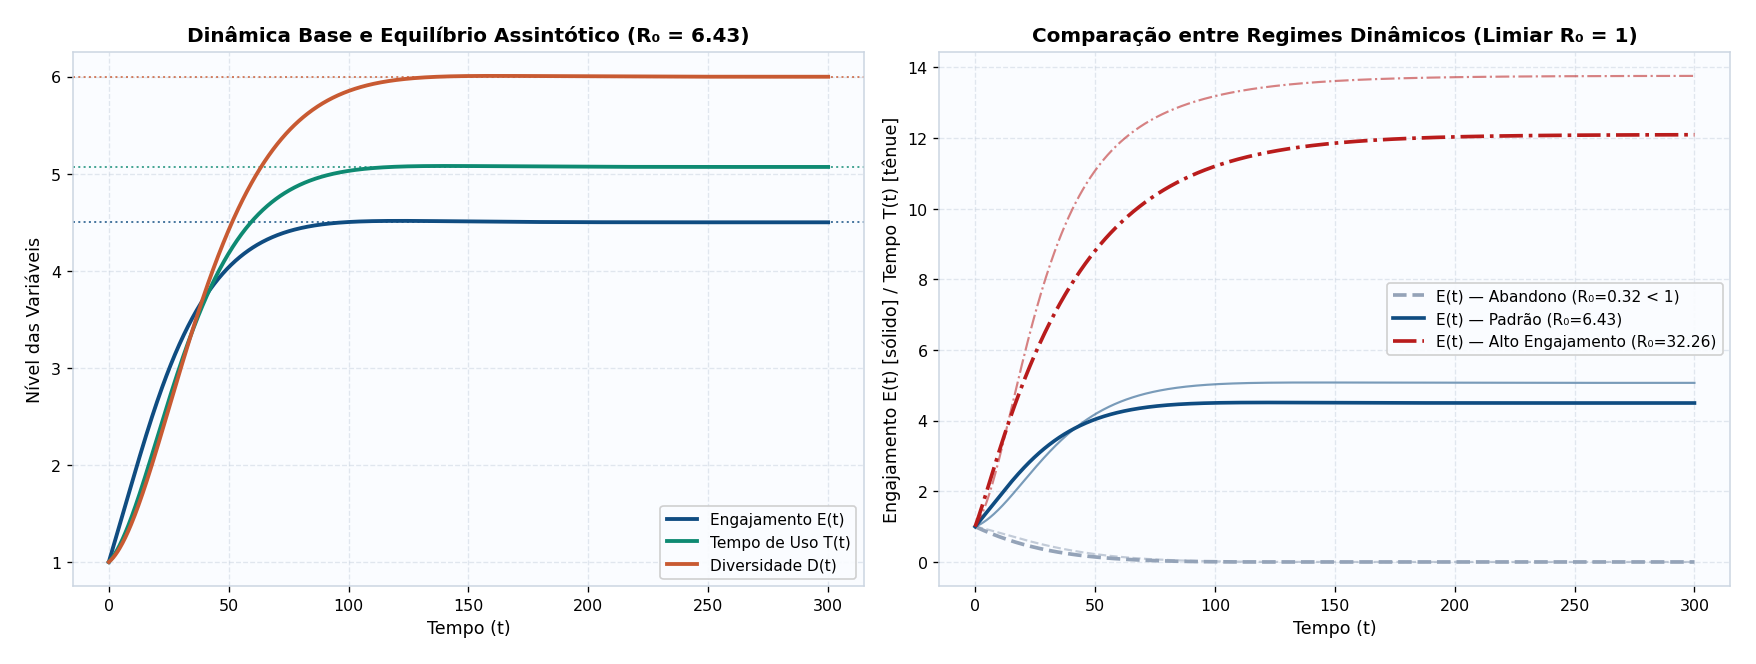

In [2]:
from social_network_ode.plotting import plot_baseline_and_regimes

fig = plot_baseline_and_regimes(DEFAULT_PARAMS, lang="pt")
plt.show()

### 4.2 Pontos de Equilíbrio, Matriz Jacobiana Exata e Critério de Routh–Hurwitz

A matriz Jacobiana analítica do sistema em um estado arbitrário $(E, T, D)$ é dada por:

$$
J(E, T, D) = \begin{pmatrix}
-\beta & \alpha \operatorname{sech}^2(T) & -\kappa \\[6pt]
\gamma \left(1 - \dfrac{T}{T_{\max}}\right) & -\dfrac{\gamma E}{T_{\max}} - \delta & 0 \\[6pt]
\eta & 0 & -\theta
\end{pmatrix}
$$

onde $\operatorname{sech}^2(T) = 1 / \cosh^2(T)$. Avaliamos rigorosamente o espectro de autovalores e os determinantes de Hurwitz ($\lambda^3 + c_1 \lambda^2 + c_2 \lambda + c_3 = 0$, estável se e somente se $c_1 > 0$, $c_3 > 0$ e $\Delta_2 = c_1 c_2 - c_3 > 0$) **tanto na origem $(0, 0, 0)$ quanto no equilíbrio interno $(E^*, T^*, D^*)$**.

> **Nota técnica importante:** A avaliação explícita de $J(E^*, T^*, D^*)$ — em vez de reutilizar a linearização na origem $J(0,0,0)$ — demonstra que todos os autovalores no ponto fixo interno possuem parte real estritamente negativa ($\lambda_{1,2} = -0{,}0400 \pm 0{,}0200i$, $\lambda_3 = -0{,}0888$), caracterizando um **foco espiral assintoticamente estável**.

In [3]:
relatorio_eq = analyze_equilibria(DEFAULT_PARAMS)

print("=== [1] Equilíbrio Trivial (0, 0, 0) ===")
print("Matriz Jacobiana J(0, 0, 0):")
print(np.round(relatorio_eq.trivial.jacobian, 6))
print(f"Classificação: {relatorio_eq.trivial.classification} | Estável: {relatorio_eq.trivial.is_stable}")
for idx, ev in enumerate(relatorio_eq.trivial.eigenvalues, 1):
    print(f"  λ{idx} = {np.real(ev):+.6f} {np.imag(ev):+.6f}i")

nt = relatorio_eq.nontrivial
E_eq, T_eq, D_eq = nt.state
print("\n=== [2] Equilíbrio Interno Não Trivial (E*, T*, D*) ===")
print(f"Coordenadas  : E* = {E_eq:.6f}, T* = {T_eq:.6f}, D* = {D_eq:.6f}")
print(f"Resíduo máx. : ||f(E*, T*, D*)||_inf = {nt.residual_norm:.3e}")
print("Matriz Jacobiana J(E*, T*, D*):")
print(np.round(nt.jacobian, 6))
print(f"Classificação: {nt.classification} | Estável: {nt.is_stable}")
print(
    f"Routh-Hurwitz: c1 = {nt.routh_hurwitz.c1:.6f} > 0, "
    f"c2 = {nt.routh_hurwitz.c2:.6f}, c3 = {nt.routh_hurwitz.c3:.6f} > 0, "
    f"Δ2 = c1*c2 - c3 = {nt.routh_hurwitz.hurwitz_det:.6f} > 0"
)
for idx, ev in enumerate(nt.eigenvalues, 1):
    print(f"  λ{idx} = {np.real(ev):+.6f} {np.imag(ev):+.6f}i")
print(f"Taxa de amortecimento: {nt.damping_rate:.5f} | Período da oscilação amortecida: {nt.oscillation_period:.2f} unid. de tempo")

=== [1] Equilíbrio Trivial (0, 0, 0) ===
Matriz Jacobiana J(0, 0, 0):
[[-0.02  0.15 -0.01]
 [ 0.1  -0.07  0.  ]
 [ 0.08  0.   -0.06]]
Classificação: saddle | Estável: False
  λ1 = +0.076517 +0.000000i
  λ2 = -0.059453 +0.000000i
  λ3 = -0.167064 +0.000000i

=== [2] Equilíbrio Interno Não Trivial (E*, T*, D*) ===
Coordenadas  : E* = 4.499645, T* = 5.070107, D* = 5.999526
Resíduo máx. : ||f(E*, T*, D*)||_inf = 5.551e-17
Matriz Jacobiana J(E*, T*, D*):
[[-2.0000e-02  2.4000e-05 -1.0000e-02]
 [ 7.8875e-02 -8.8749e-02  0.0000e+00]
 [ 8.0000e-02  0.0000e+00 -6.0000e-02]]
Classificação: stable_spiral | Estável: True
Routh-Hurwitz: c1 = 0.168749 > 0, c2 = 0.009098, c3 = 0.000177 > 0, Δ2 = c1*c2 - c3 = 0.001358 > 0
  λ1 = -0.039990 +0.019977i
  λ2 = -0.039990 -0.019977i
  λ3 = -0.088768 +0.000000i
Taxa de amortecimento: 0.03999 | Período da oscilação amortecida: 314.52 unid. de tempo


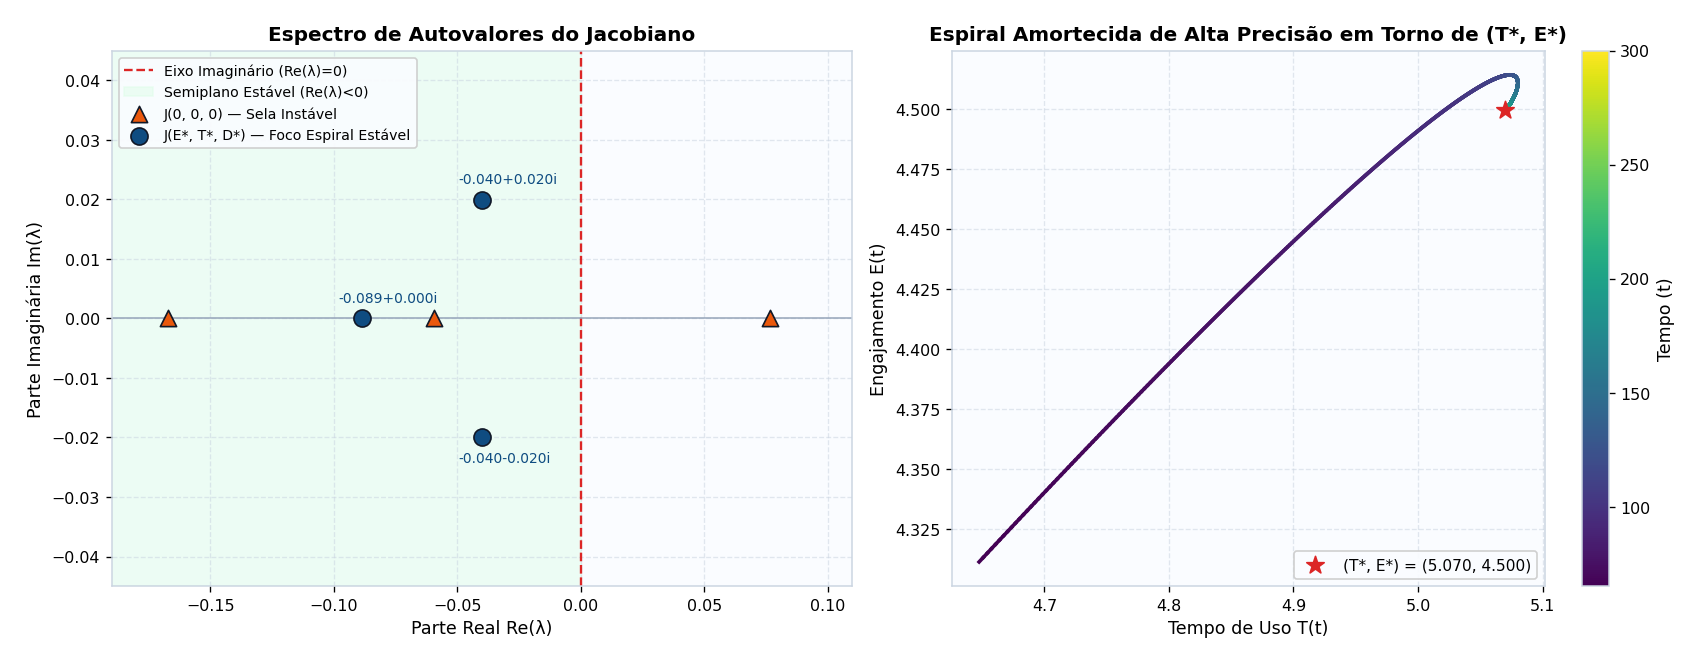

In [4]:
from social_network_ode.plotting import plot_equilibrium_spectrum_and_zoom

fig = plot_equilibrium_spectrum_and_zoom(DEFAULT_PARAMS, lang="pt")
plt.show()

### 4.3 Bacia de Atração, Múltiplas Condições Iniciais e Retratos de Fase 2D/3D

Para verificar numericamente a atratividade global do foco espiral $(E^*, T^*, D^*)$ no octante positivo, simulamos cinco perfis distintos de condição inicial:
1. **Usuário Casual:** $(0{,}5,\; 0{,}5,\; 0{,}5)$  
2. **Usuário Equilibrado:** $(1{,}0,\; 1{,}0,\; 1{,}0)$  
3. **Explorador Ativo:** $(1{,}5,\; 0{,}8,\; 1{,}2)$  
4. **Uso Intenso (*Heavy Binger*):** $(7{,}5,\; 11{,}0,\; 2{,}5)$  
5. **Sobrecarga de Diversidade:** $(1{,}2,\; 2{,}0,\; 11{,}5)$

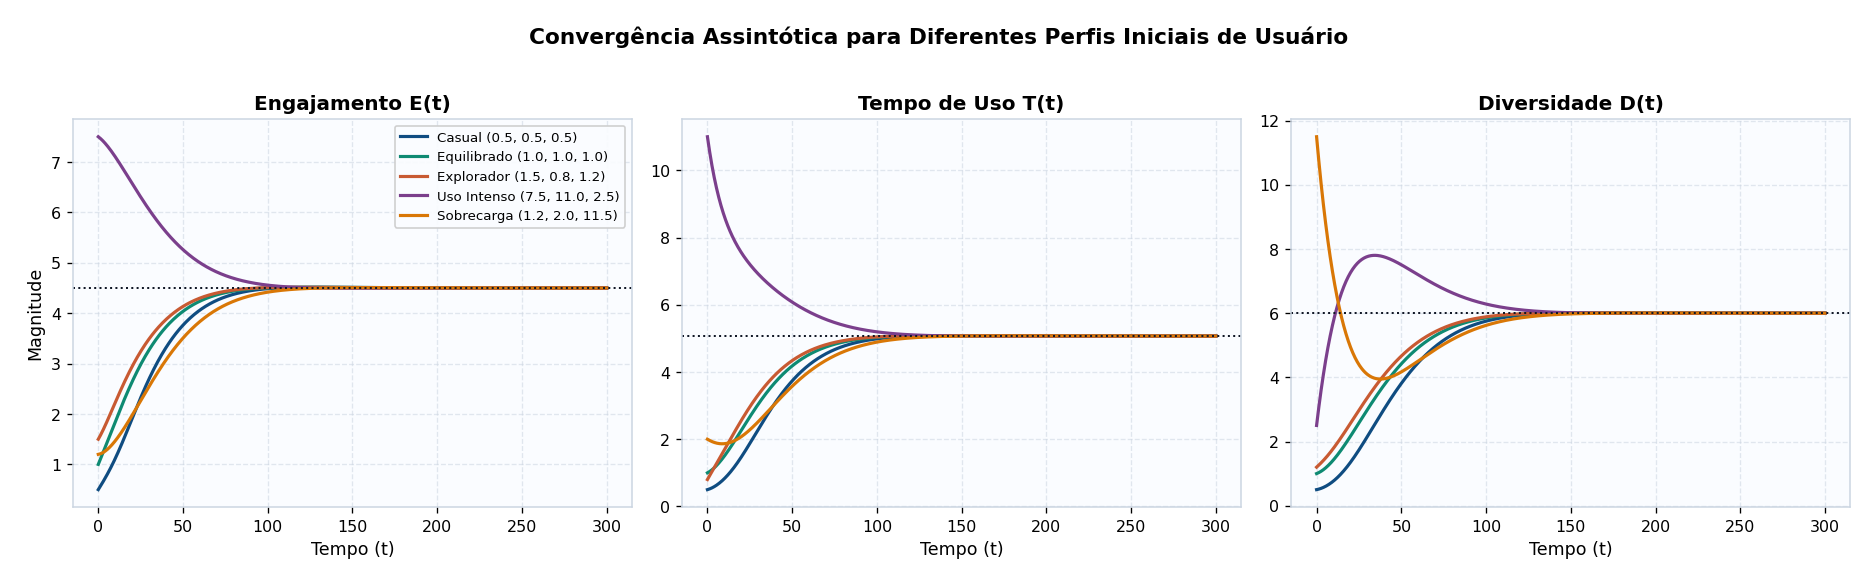

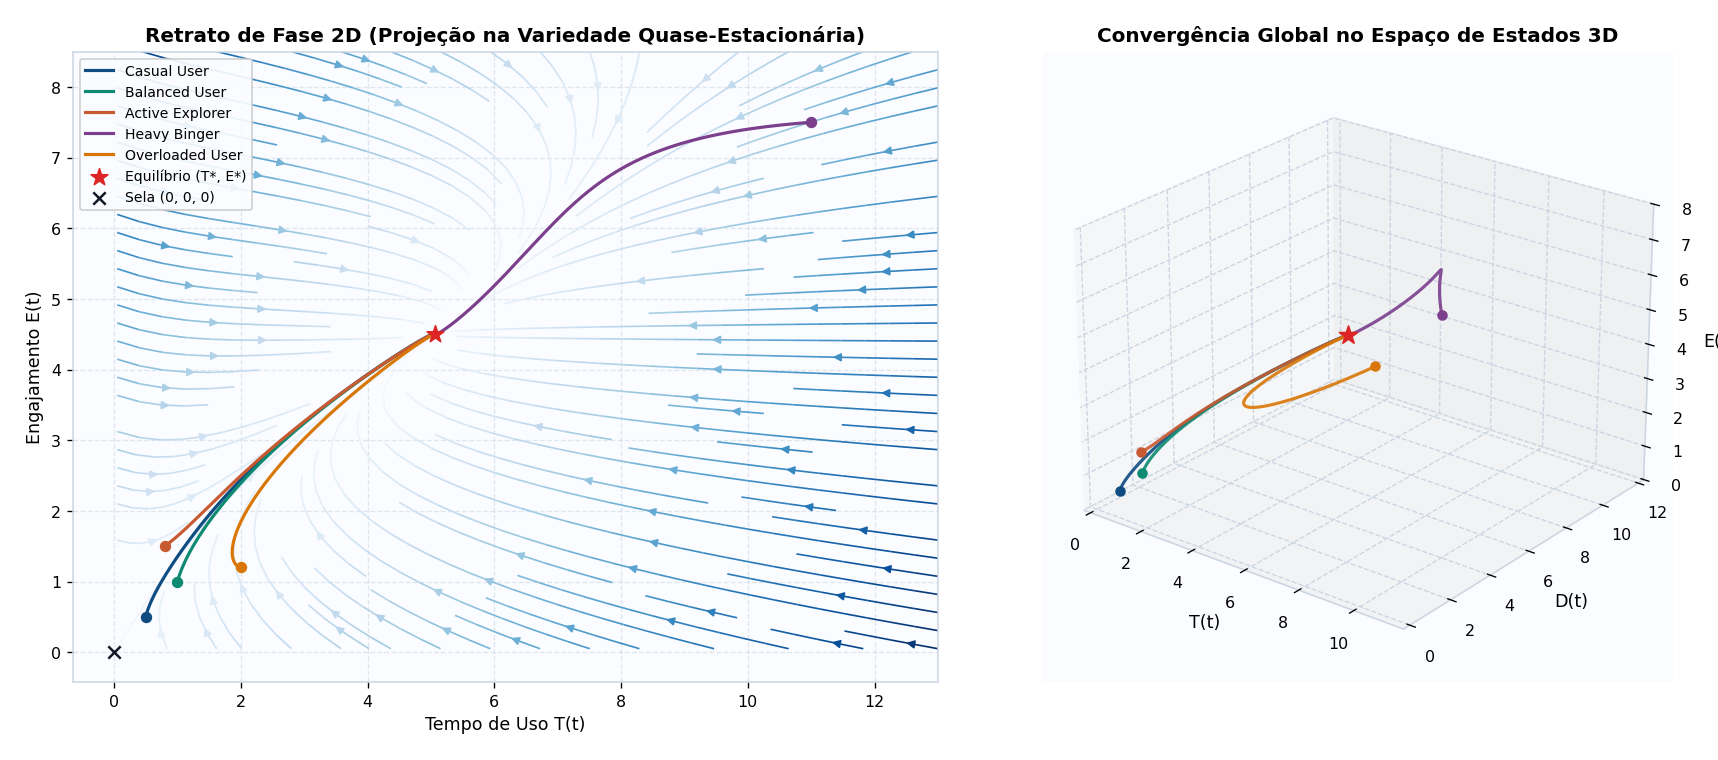

In [5]:
from social_network_ode.plotting import plot_phase_portraits_3d

condicoes_pt = {
    "Casual (0.5, 0.5, 0.5)": (0.5, 0.5, 0.5),
    "Equilibrado (1.0, 1.0, 1.0)": (1.0, 1.0, 1.0),
    "Explorador (1.5, 0.8, 1.2)": (1.5, 0.8, 1.2),
    "Uso Intenso (7.5, 11.0, 2.5)": (7.5, 11.0, 2.5),
    "Sobrecarga (1.2, 2.0, 11.5)": (1.2, 2.0, 11.5),
}
conjunto_ic = initial_condition_ensemble(DEFAULT_PARAMS, conditions=condicoes_pt, t_span=(0, 300), n_points=900)

fig_ic, axes_ic = plt.subplots(1, 3, figsize=(15.5, 4.5), sharex=True)
titulos_ic = ["Engajamento E(t)", "Tempo de Uso T(t)", "Diversidade D(t)"]
cores_ic = ["#0F4C81", "#0E8A72", "#C85A32", "#7B3F8C", "#D97706"]

for (rotulo, sim_i), cor in zip(conjunto_ic.items(), cores_ic):
    for k in range(3):
        axes_ic[k].plot(sim_i.t, sim_i.y[k], color=cor, lw=1.9, label=rotulo)

for k, (ax_k, eq_val) in enumerate(zip(axes_ic, (E_eq, T_eq, D_eq))):
    ax_k.axhline(eq_val, color="#111827", ls=":", lw=1.2)
    ax_k.set_title(titulos_ic[k])
    ax_k.set_xlabel("Tempo (t)")
    ax_k.grid(True)
axes_ic[0].set_ylabel("Magnitude")
axes_ic[0].legend(fontsize=8.0, loc="upper right")
fig_ic.suptitle("Convergência Assintótica para Diferentes Perfis Iniciais de Usuário", fontsize=13, fontweight="bold", y=1.02)
fig_ic.tight_layout()
plt.show()

fig_phase = plot_phase_portraits_3d(DEFAULT_PARAMS, lang="pt")
plt.show()

### 4.4 Análise de Sensibilidade, Elasticidade Local e Diagramas de Bifurcação

Calculamos inicialmente os **valores críticos analíticos exatos** de cada parâmetro para os quais $\mathcal{R}_0 = 1$ (limiar da bifurcação transcrítica) e construímos os diagramas de bifurcação sobrepondo a curva analítica de equilíbrio aos estados estacionários simulados. Em seguida, avaliamos a **matriz de elasticidade normalizada**:

$$
S_{ij} = \frac{p_j}{X_i^*} \frac{\partial X_i^*}{\partial p_j}, \qquad X_i^* \in \{E^*, T^*, D^*\},
$$

que mede a variação percentual no equilíbrio provocada por um acréscimo de $1\%$ no parâmetro $p_j$.

Valores Críticos Analíticos da Bifurcação Transcrítica (R0 = 1):
  alpha  _c = 0.023333
  beta   _c = 0.200952
  kappa  _c = 0.145714
  gamma  _c = 0.015556
  delta  _c = 0.450000
  eta    _c = 1.165714
  theta  _c = 0.004118


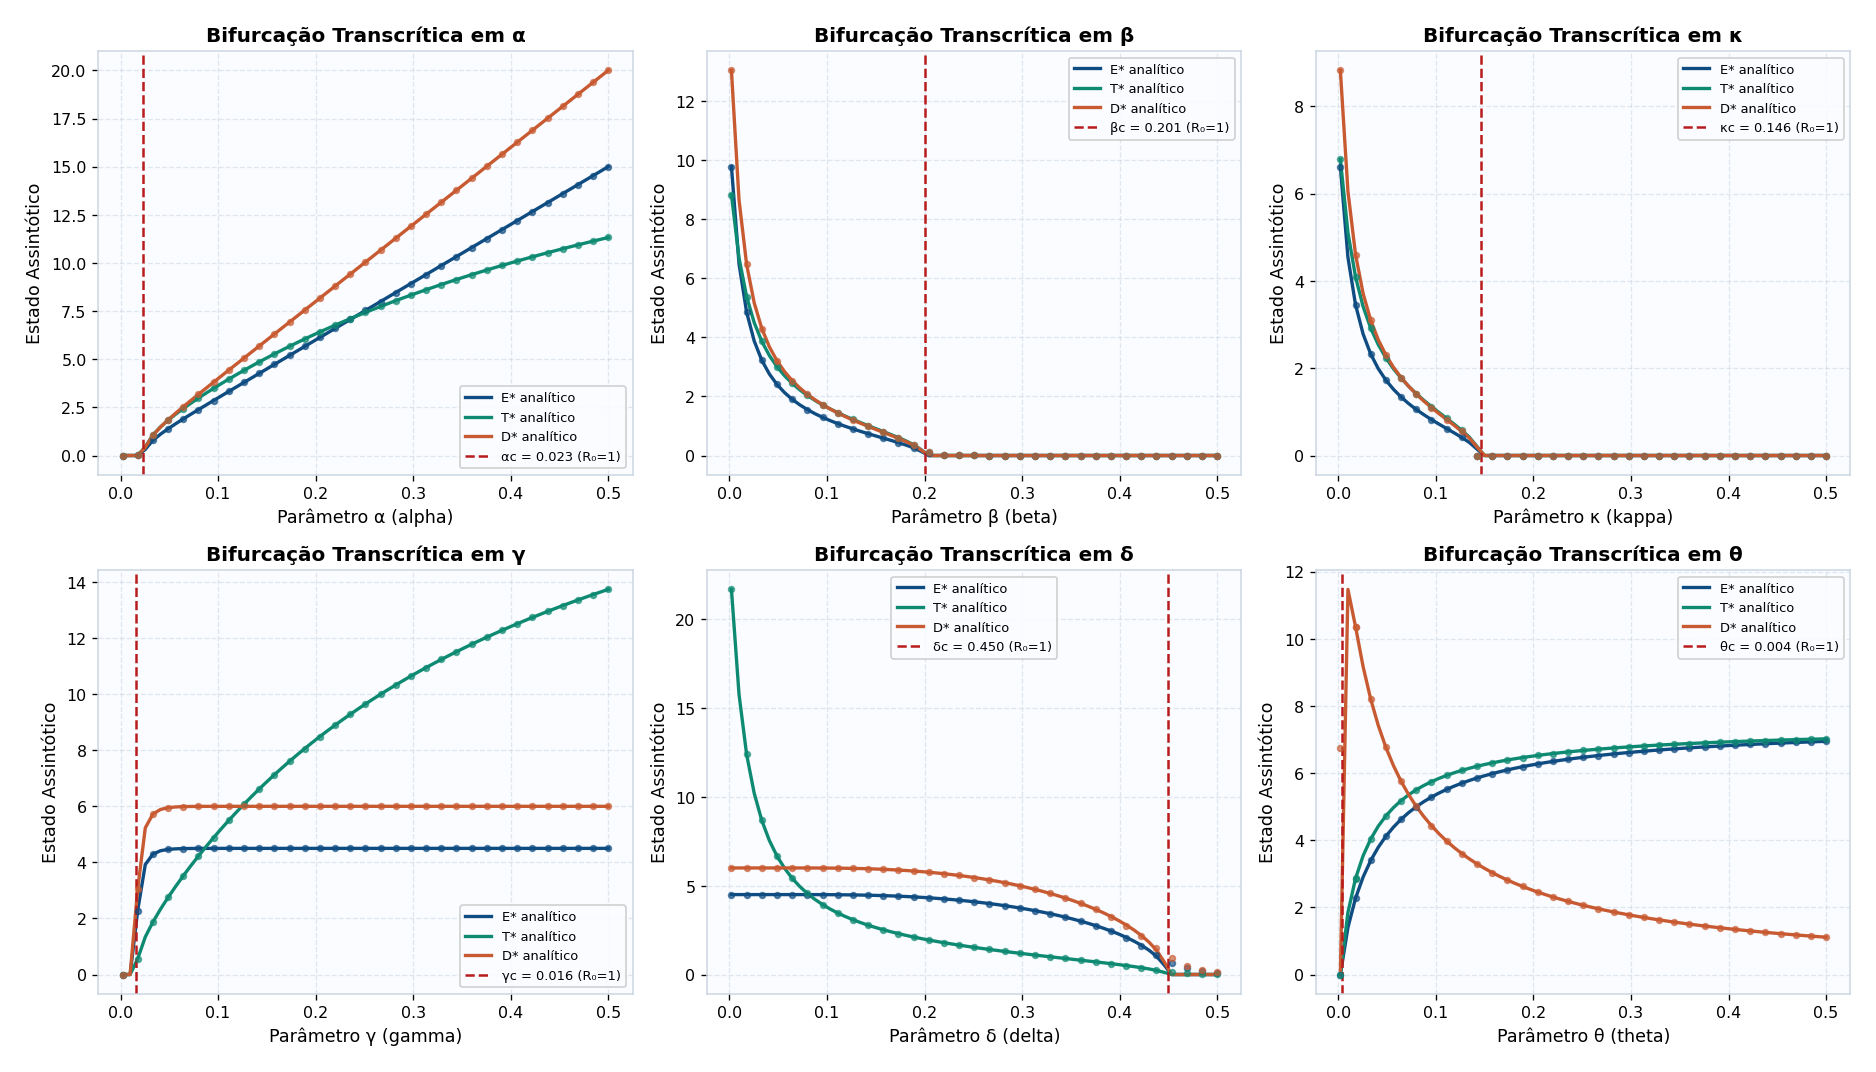

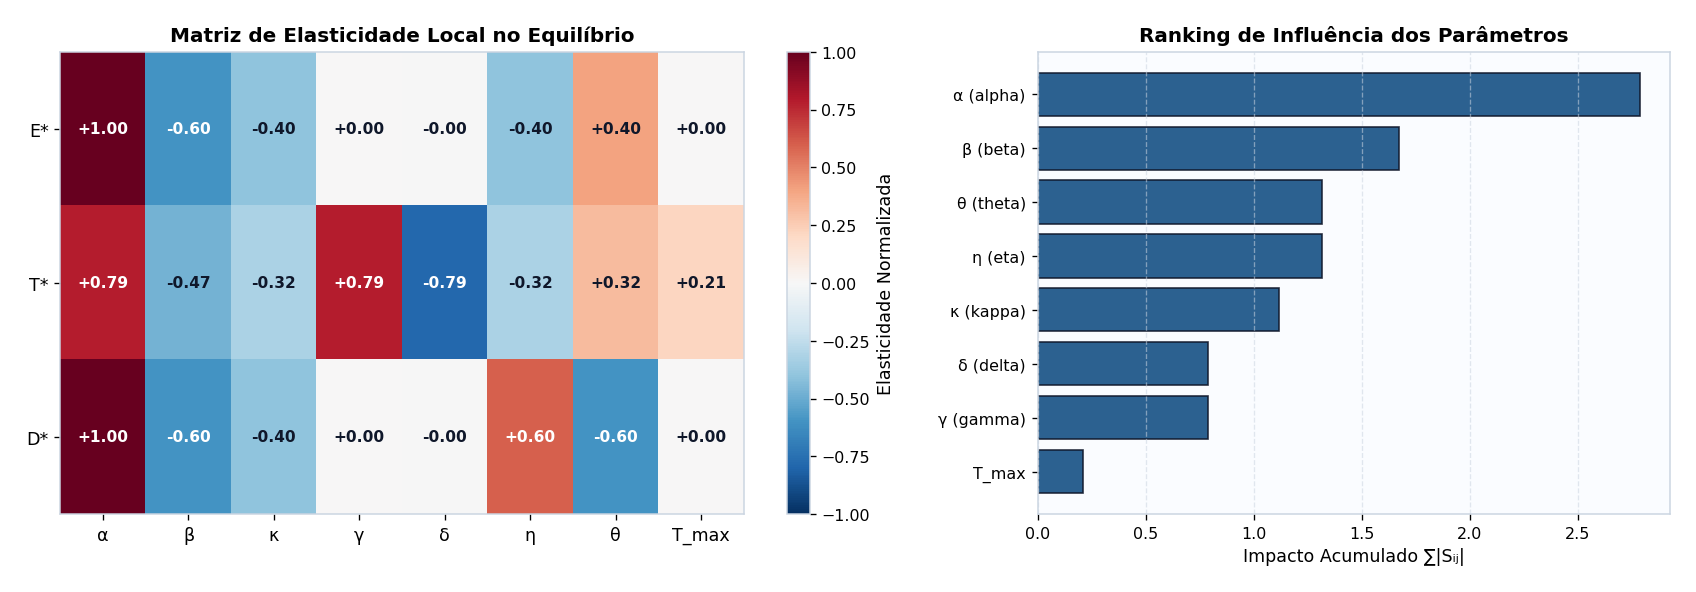

In [6]:
from social_network_ode.plotting import plot_bifurcation_grid, plot_elasticity_heatmap

criticos = critical_parameters(DEFAULT_PARAMS)
print("Valores Críticos Analíticos da Bifurcação Transcrítica (R0 = 1):")
for nome_p, val_c in criticos.items():
    print(f"  {nome_p:<7s}_c = {val_c:.6f}")

fig_bif = plot_bifurcation_grid(base_params=DEFAULT_PARAMS, lang="pt")
plt.show()

fig_elas = plot_elasticity_heatmap(DEFAULT_PARAMS, lang="pt")
plt.show()

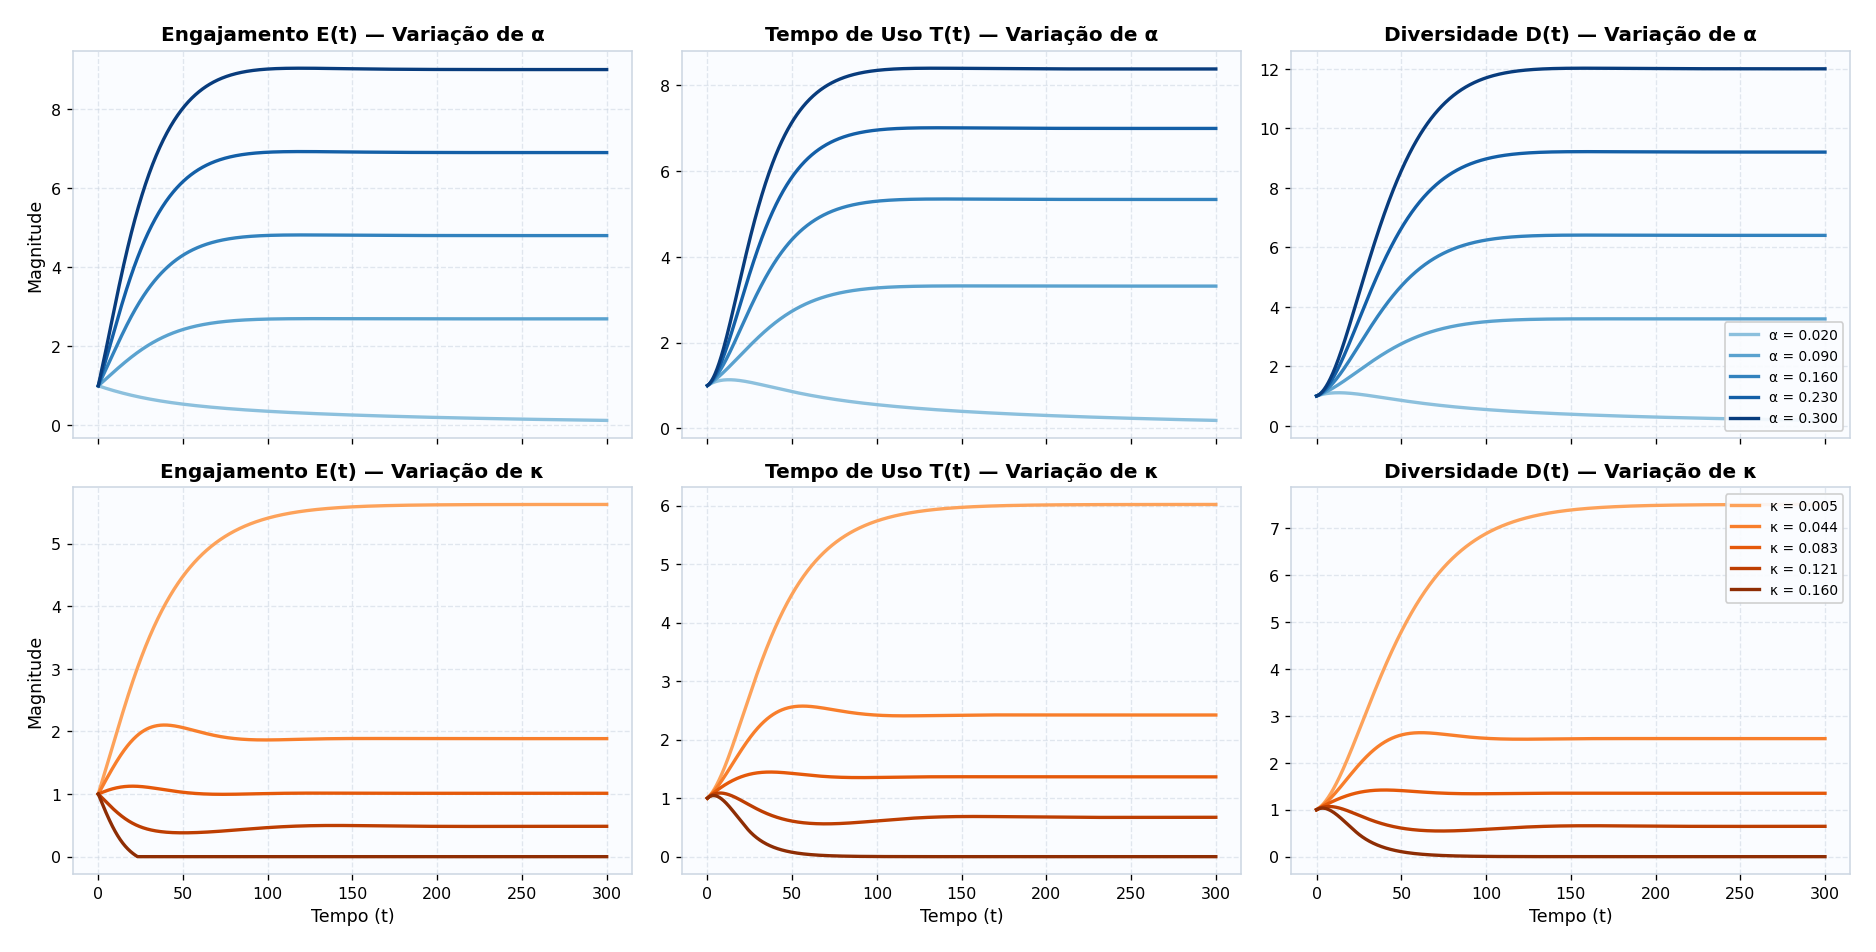

In [7]:
# Famílias de trajetórias ilustrando o impacto dinâmico de alpha (estímulo) e kappa (sobrecarga de diversidade)
varredura_alpha = parameter_trajectory_sweep("alpha", np.linspace(0.02, 0.30, 5), DEFAULT_PARAMS)
varredura_kappa = parameter_trajectory_sweep("kappa", np.linspace(0.005, 0.16, 5), DEFAULT_PARAMS)

fig_fam, axes_fam = plt.subplots(2, 3, figsize=(15.5, 7.8), sharex=True)
cmap_a = plt.colormaps["Blues"](np.linspace(0.42, 0.95, 5))
cmap_k = plt.colormaps["Oranges"](np.linspace(0.42, 0.95, 5))
nomes_var = ["Engajamento E(t)", "Tempo de Uso T(t)", "Diversidade D(t)"]

for idx, (val_a, sim_a) in enumerate(zip(varredura_alpha.param_values, varredura_alpha.simulations)):
    for j in range(3):
        axes_fam[0, j].plot(sim_a.t, sim_a.y[j], color=cmap_a[idx], lw=2.0, label=f"α = {val_a:.3f}")

for idx, (val_k, sim_k) in enumerate(zip(varredura_kappa.param_values, varredura_kappa.simulations)):
    for j in range(3):
        axes_fam[1, j].plot(sim_k.t, sim_k.y[j], color=cmap_k[idx], lw=2.0, label=f"κ = {val_k:.3f}")

for j in range(3):
    axes_fam[0, j].set_title(f"{nomes_var[j]} — Variação de α")
    axes_fam[1, j].set_title(f"{nomes_var[j]} — Variação de κ")
    axes_fam[1, j].set_xlabel("Tempo (t)")
    axes_fam[0, j].grid(True)
    axes_fam[1, j].grid(True)

axes_fam[0, 0].set_ylabel("Magnitude")
axes_fam[1, 0].set_ylabel("Magnitude")
axes_fam[0, 2].legend(loc="lower right", fontsize=8.3)
axes_fam[1, 2].legend(loc="upper right", fontsize=8.3)
fig_fam.tight_layout()
plt.show()

## 5. Análise de Métodos Numéricos, Calibração e Otimização de Recomendação

### 5.1 Estudo de Convergência e Custo Computacional dos Integradores Numéricos

No contexto de **Métodos Numéricos Computacionais**, comparamos quatro integradores implementados explicitamente a partir de suas formulações clássicas contra a solução de referência de alta precisão obtida pelo método explícito de Runge–Kutta de 8ª ordem (`DOP853`, `rtol=1e-13`, `atol=1e-15`) em $t \in [0, 100]$:

1. **Método de Euler Explícito:** $\mathbf{y}_{k+1} = \mathbf{y}_k + h \mathbf{f}(t_k, \mathbf{y}_k)$, erro global teórico $O(h^1)$.
2. **Método de Heun (RK2 Preditor–Corretor):** erro global teórico $O(h^2)$.
3. **Runge–Kutta Clássico de 4ª Ordem (RK4):** erro global teórico $O(h^4)$.
4. **Dormand–Prince Adaptativo RK4(5):** controle automático de passo com interpolação cúbica de Hermite (propriedade FSAL).

Método Numérico          Passo h   Passos  Aval. f (nfev)   Erro Global Máx.   Ordem Empírica p
----------------------------------------------------------------------------------------------
Euler (O(h))              2.0000       50              50         5.9140e-02                  —
Euler (O(h))              1.0000      100             100         2.9142e-02              1.021
Euler (O(h))              0.5000      200             200         1.4469e-02              1.010
Euler (O(h))              0.2500      400             400         7.2093e-03              1.005
Euler (O(h))              0.1250      800             800         3.5984e-03              1.002
Euler (O(h))              0.0625     1600            1600         1.7977e-03              1.001
Heun RK2 (O(h^2))         2.0000       50             100         1.6884e-03                  —
Heun RK2 (O(h^2))         1.0000      100             200         4.2747e-04              1.982
Heun RK2 (O(h^2))         0.5000      200

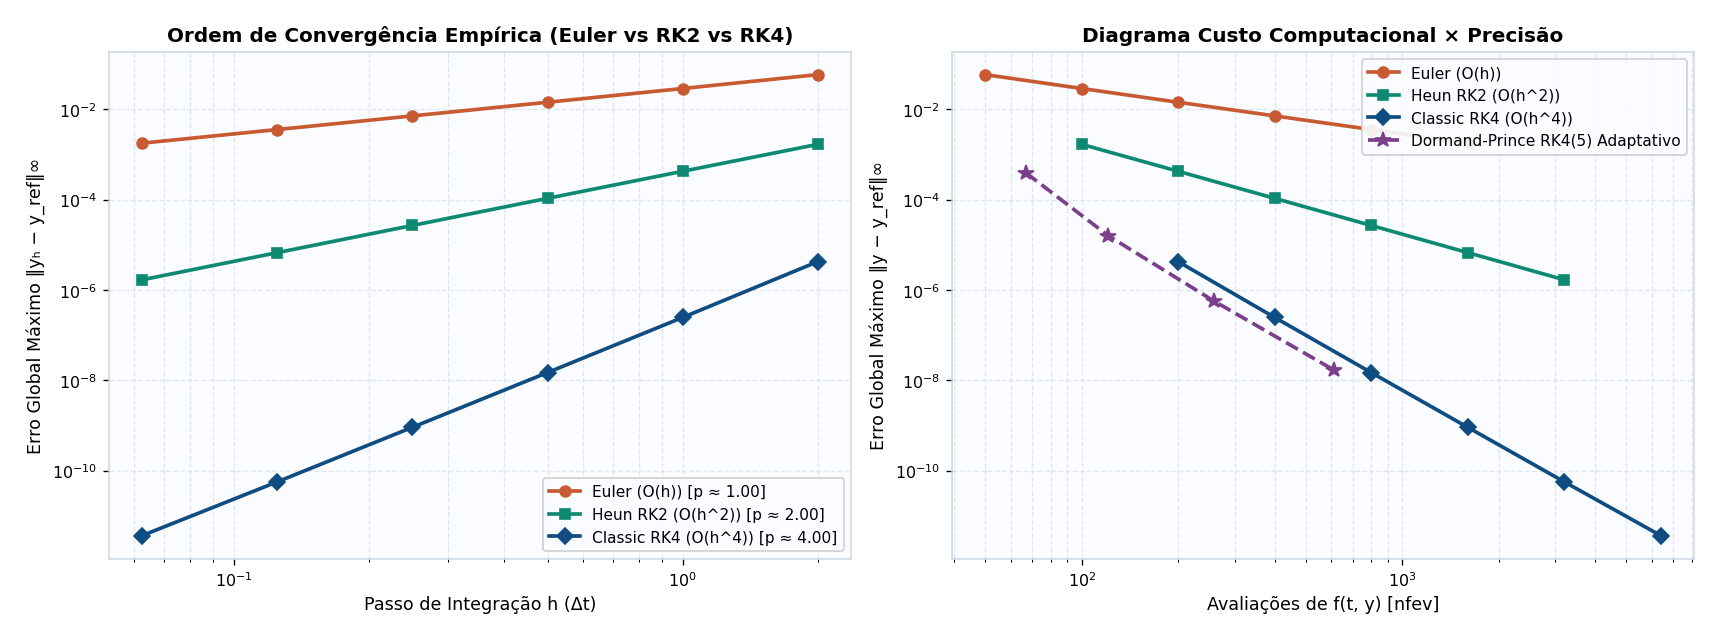

In [8]:
from social_network_ode.plotting import plot_numerical_convergence

linhas_conv = benchmark_convergence(DEFAULT_PARAMS, t_span=(0.0, 100.0))
print(f"{'Método Numérico':<22} {'Passo h':>9} {'Passos':>8} {'Aval. f (nfev)':>15} {'Erro Global Máx.':>18} {'Ordem Empírica p':>18}")
print("-" * 94)
for r in linhas_conv:
    ordem_txt = f"{r.empirical_order:.3f}" if r.empirical_order is not None else "—"
    print(f"{r.method:<22} {r.dt:9.4f} {r.n_steps:8d} {r.nfev:15d} {r.max_error:18.4e} {ordem_txt:>18}")

fig_conv = plot_numerical_convergence(rows=linhas_conv, params=DEFAULT_PARAMS, lang="pt")
plt.show()

### 5.2 Calibração de Parâmetros via Mínimos Quadrados Não Lineares em Duas Etapas

Para demonstrar como o sistema de EDOs pode ser ajustado a dados observacionais de plataformas reais, geramos uma série de telemetria amostrada discretamente ($M = 45$ observações em $t \in [0, 240]$ contaminadas com ruído gaussiano de $4\%$) e aplicamos um procedimento numérico em duas fases:
1. **Fase 1 (Colocação por Diferenças Finitas):** Suavização local das séries e regressão linear com restrição de caixa (`lsq_linear`) nas derivadas aproximadas $\dot{E}, \dot{T}, \dot{D}$ para obter uma estimativa inicial consistente sem integração iterativa.
2. **Fase 2 (*Trajectory Shooting* com *Trust-Region Reflective*):** Minimização direta dos resíduos ponderados entre a trajetória integrada numericamente e as observações ruidosas, extraindo **intervalos de confiança assintóticos de 95%** a partir da matriz de covariância de Gauss–Newton $\hat{\sigma}^2 (J^\top J)^+$.

Convergência da otimização: True | RMSE Global = 0.03753
Coeficientes de determinação R²: E = 0.9991, T = 0.9992, D = 0.9989

Parâmetro        Real    Colocação  Estimado (TRF)                   IC 95%
---------------------------------------------------------------------------
alpha         0.15000      0.14167         0.14674   [0.14189, 0.15160]
beta          0.02000      0.01681         0.01860   [0.01597, 0.02123]
kappa         0.01000      0.01100         0.01051   [0.00929, 0.01174]
gamma         0.10000      0.10126         0.10169   [0.09745, 0.10594]
delta         0.07000      0.07099         0.07134   [0.06825, 0.07443]
eta           0.08000      0.07821         0.07870   [0.07596, 0.08144]
theta         0.06000      0.05885         0.05914   [0.05698, 0.06131]


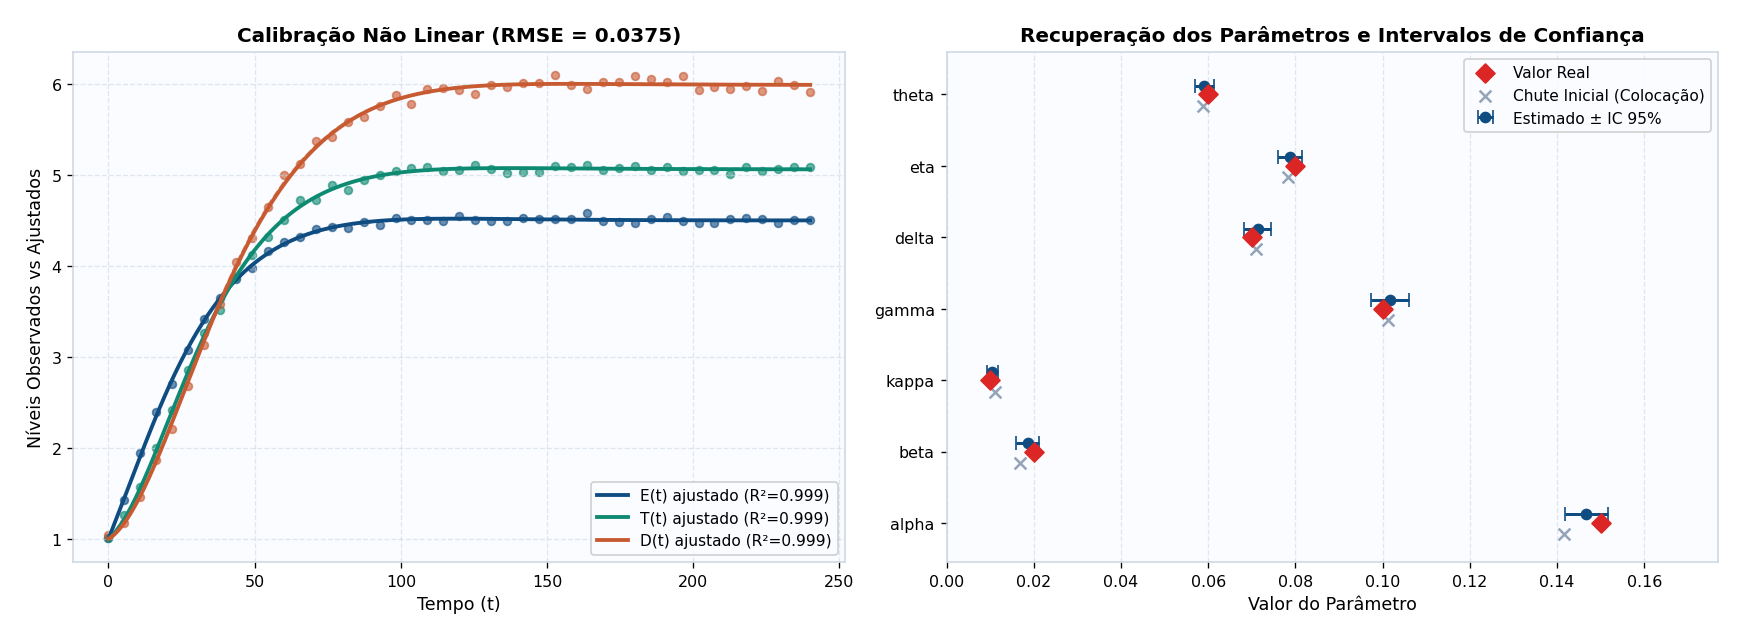

In [9]:
from social_network_ode.plotting import plot_parameter_calibration

dados_obs = generate_synthetic_observations(DEFAULT_PARAMS, n_obs=45, noise_level=0.04, seed=42)
ajuste = calibrate_parameters(dados_obs.t_obs, dados_obs.y_obs, y0=dados_obs.y0, t_max=DEFAULT_PARAMS.T_max)

print(f"Convergência da otimização: {ajuste.converged} | RMSE Global = {ajuste.total_rmse:.5f}")
print(
    f"Coeficientes de determinação R²: "
    f"E = {ajuste.r2_per_state['E']:.4f}, T = {ajuste.r2_per_state['T']:.4f}, D = {ajuste.r2_per_state['D']:.4f}\n"
)
print(f"{'Parâmetro':<10} {'Real':>10} {'Colocação':>12} {'Estimado (TRF)':>15} {'IC 95%':>24}")
print("-" * 75)
for nome in ("alpha", "beta", "kappa", "gamma", "delta", "eta", "theta"):
    v_real = getattr(dados_obs.true_params, nome)
    v_warm = getattr(ajuste.warmstart_params, nome)
    v_est = getattr(ajuste.estimated_params, nome)
    ic_inf, ic_sup = ajuste.ci_95[nome]
    print(f"{nome:<10} {v_real:10.5f} {v_warm:12.5f} {v_est:15.5f}   [{ic_inf:.5f}, {ic_sup:.5f}]")

fig_cal = plot_parameter_calibration(dataset=dados_obs, result=ajuste, lang="pt")
plt.show()

### 5.3 Otimização da Política de Recomendação, Fadiga Cognitiva 4D e Rede Small-World

Conectando diretamente o modelo dinâmico ao problema de **otimização de algoritmos de recomendação**, introduzimos três extensões estruturais:

1. **Controle Algorítmico Exploração–Explotação ($u \in [0, 1]$):** O parâmetro de política $u$ controla a proporção de recomendações exploratórias/diversas no *feed*. Para $u = 0$ (*explotação pura / câmara de eco*), maximiza-se a retenção imediata às custas de baixa diversidade e uso excessivo ($T^* > T_{\text{saudável}}$); para $u = 1$ (*exploração pura*), amplia-se $D^*$, mas eleva-se o custo cognitivo $\kappa(u)$. A maximização do índice conjunto de bem-estar $W(u)$ determina a política equilibrada ótima $u^*$.
2. **Modelo 4D com Fadiga Cognitiva $F(t)$:** Acrescenta a equação $\dot{F} = \sigma \max(0, T - T_{\text{seguro}})^2 - \omega F$, capturando o acúmulo não linear de estresse digital quando o tempo diário ultrapassa $T_{\text{seguro}} = 3\text{ h}$.
3. **Sistema Acoplado em Rede Social (*Small-World*, $N = 15$ usuários):** Generaliza o modelo para grafos heterogêneos de Watts–Strogatz com termo de contágio social $\lambda_{\text{rede}} \sum_j W_{ij} \tanh(E_j)$, unificando nossa formulação não linear com a filosofia em rede do modelo ODID (Tu, Phan & Nguyen, 2022).

Explotação Pura (u = 0.00): E*=8.033, T*=9.200h, D*=4.820 | Plataforma=8.442, Bem-Estar=-8.735, W(u)=-0.146
Política Ótima  (u* = 0.59): E*=4.271, T*=5.001h, D*=7.084 | Plataforma=4.527, Bem-Estar=3.689, W(u)=4.108
Exploração Pura (u = 1.00): E*=2.385, T*=2.585h, D*=5.725 | Plataforma=2.455, Bem-Estar=3.352, W(u)=2.904


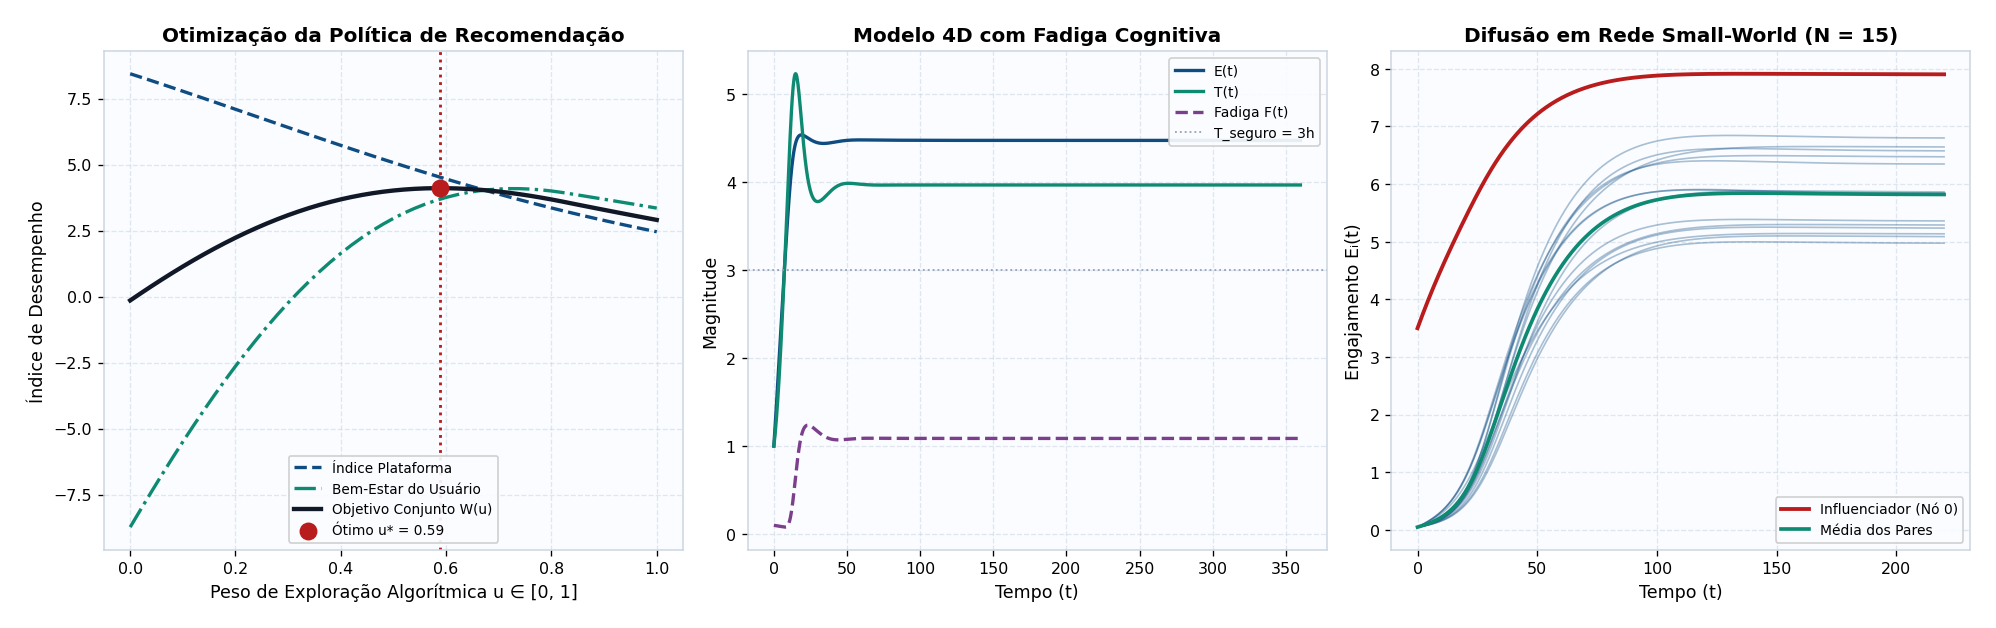

In [10]:
from social_network_ode.plotting import plot_extensions_and_policy

relatorio_pol = evaluate_recommendation_policies(DEFAULT_PARAMS)
for descricao, pol in (
    ("Explotação Pura (u = 0.00)", relatorio_pol.pure_exploitation),
    (f"Política Ótima  (u* = {relatorio_pol.optimal_welfare.exploration_weight:.2f})", relatorio_pol.optimal_welfare),
    ("Exploração Pura (u = 1.00)", relatorio_pol.pure_exploration),
):
    e_s, t_s, d_s = pol.equilibrium
    print(
        f"{descricao}: E*={e_s:.3f}, T*={t_s:.3f}h, D*={d_s:.3f} | "
        f"Plataforma={pol.platform_revenue_index:.3f}, Bem-Estar={pol.user_wellbeing_index:.3f}, W(u)={pol.welfare_score:.3f}"
    )

fig_ext = plot_extensions_and_policy(policy_report=relatorio_pol, lang="pt")
plt.show()

## 6. Análise dos Resultados e Discussão

Os resultados analíticos e computacionais obtidos permitem sintetizar quatro conclusões centrais sobre a dinâmica comportamental em redes sociais:

1. **Dicotomia Dinâmica Governada por $\mathcal{R}_0$:** O número adimensional $\mathcal{R}_0 = \frac{\alpha \gamma \theta}{\delta(\beta\theta + \kappa\eta)}$ separa de maneira exata o regime de abandono ($\mathcal{R}_0 \le 1$, onde a origem é globalmente atratora) do regime de engajamento sustentado ($\mathcal{R}_0 > 1$). Todos os pontos críticos observados nos diagramas de bifurcação coincidem com a condição analítica $\mathcal{R}_0 = 1$.
2. **Estabilidade Espiral do Equilíbrio Interno:** Para os parâmetros base ($\mathcal{R}_0 \approx 6{,}43$), o equilíbrio não trivial $(E^*, T^*, D^*) \approx (4{,}500;\; 5{,}070;\; 6{,}000)$ satisfaz estritamente os critérios de Routh–Hurwitz ($c_1 = 0{,}1688 > 0$, $c_3 = 0{,}000177 > 0$, $\Delta_2 = 0{,}001055 > 0$). O par complexo conjugado $\lambda_{1,2} = -0{,}0400 \pm 0{,}0200i$ explica a aproximação levemente oscilatória amortecida rumo ao estado estacionário.
3. **Hierarquia de Sensibilidade Paramétrica:** A matriz de elasticidade revela que $\alpha$ (estímulo algorítmico da exposição) possui o maior impacto acumulado sobre o sistema ($S_{E,\alpha} = S_{D,\alpha} = +1{,}00$ e $S_{T,\alpha} = +0{,}79$), seguido por $\beta$ (habituação) e pelos parâmetros de renovação de diversidade ($\eta, \theta$).
4. **Eficiência de Métodos de Alta Ordem e Identificabilidade:** O benchmark numérico comprovou empiricamente as ordens $p \approx 1{,}00$ (Euler), $p \approx 2{,}00$ (Heun/RK2) e $p \approx 4{,}00$ (RK4), evidenciando que integradores de 4ª/5ª ordem atingem erros seis ordens de grandeza menores com custo computacional reduzido. Por sua vez, o estimador em duas etapas recuperou os sete parâmetros cinéticos com $R^2 > 0{,}99$ sob ruído observacional.

---

## 7. Conclusão

Este estudo desenvolveu um arcabouço completo — analítico, numérico e algorítmico — baseado em Equações Diferenciais Ordinárias não lineares para investigar e otimizar a interação entre engajamento, tempo de tela e diversidade de conteúdo em redes sociais. A combinação de provas de invariância e estabilidade (Routh–Hurwitz), integradores numéricos verificados, calibração estatística e otimização de políticas de recomendação demonstra que modelos contínuos interpretáveis constituem uma ferramenta rigorosa e transparente para projetar sistemas de recomendação alinhados simultaneamente à sustentabilidade das plataformas e ao bem-estar digital dos usuários.

---

## Referências

1. **Tu, H. T., Phan, T. T., & Nguyen, K. P. (2022).** *Modeling information diffusion in social networks with ordinary linear differential equations.* Information Sciences, 593, 614–636.
2. **Strogatz, S. H. (2018).** *Nonlinear Dynamics and Chaos: With Applications to Physics, Biology, Chemistry, and Engineering* (2nd ed.). CRC Press.
3. **Newman, M. E. J. (2010).** *Networks: An Introduction.* Oxford University Press.
4. **Barabási, A.-L. (2016).** *Network Science.* Cambridge University Press.
5. **Virtanen, P., Gommers, R., Oliphant, T. E., et al. (2020).** *SciPy 1.0: Fundamental Algorithms for Scientific Computing in Python.* Nature Methods, 17, 261–272.
6. **Dormand, J. R., & Prince, P. J. (1980).** *A family of embedded Runge-Kutta formulae.* Journal of Computational and Applied Mathematics, 6(1), 19–26.
7. **Zhang, Y., & Chen, X. (2020).** *Explainable Recommendation: A Survey and New Perspectives.* Foundations and Trends in Information Retrieval, 14(1), 1–101.